# DDIM From Scratch in PyTorch

This independent notebook trains its own MNIST noise-prediction U-Net, then compares DDIM and DDPM samplers using that same model and schedule. It requires no other notebook or existing checkpoint. Run top to bottom; MNIST downloads if needed. Training duration and sample quality depend on configuration and hardware.

## 1. Environment and device

Import required libraries, report versions, and select CUDA when available.

In [1]:
import math, random, time
from pathlib import Path
from typing import Optional
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
NumPy: 2.1.3
CUDA available: True
Selected device: cuda


## 2. Configuration

All configurable parameters are here. `num_timesteps` is the training schedule length; `inference_steps` controls DDIM's shorter inference trajectory. This notebook uses its own checkpoint directory.

In [2]:
CONFIG = {
 "seed":42,"batch_size":128,"epochs":20,"learning_rate":2e-4,
 "num_timesteps":300,"beta_start":1e-4,"beta_end":0.02,"base_channels":32,"num_workers":2,
 "checkpoint_dir":"checkpoints_ddim_from_scratch","checkpoint_name":"ddim_mnist.pt","resume":False,
 "sample_every_epochs":1,"sample_count":16,"inference_steps":[25,50,100],"ddim_eta":0.0,"show_progress":True}
SEED=int(CONFIG["seed"]); random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
BATCH_SIZE=int(CONFIG["batch_size"]); NUM_TIMESTEPS=int(CONFIG["num_timesteps"])
CHECKPOINT_DIR=Path(CONFIG["checkpoint_dir"]); CHECKPOINT_DIR.mkdir(parents=True,exist_ok=True)
CHECKPOINT_PATH=CHECKPOINT_DIR/CONFIG["checkpoint_name"]
print("Configuration:",CONFIG); print("Checkpoint:",CHECKPOINT_PATH)

Configuration: {'seed': 42, 'batch_size': 128, 'epochs': 20, 'learning_rate': 0.0002, 'num_timesteps': 300, 'beta_start': 0.0001, 'beta_end': 0.02, 'base_channels': 32, 'num_workers': 2, 'checkpoint_dir': 'checkpoints_ddim_from_scratch', 'checkpoint_name': 'ddim_mnist.pt', 'resume': False, 'sample_every_epochs': 1, 'sample_count': 16, 'inference_steps': [25, 50, 100], 'ddim_eta': 0.0, 'show_progress': True}
Checkpoint: checkpoints_ddim_from_scratch/ddim_mnist.pt


## 3. MNIST dataset

`ToTensor` maps pixels to `[0,1]`; normalization maps them to `[-1,1]`. The loader shuffles examples and pins memory on CUDA.

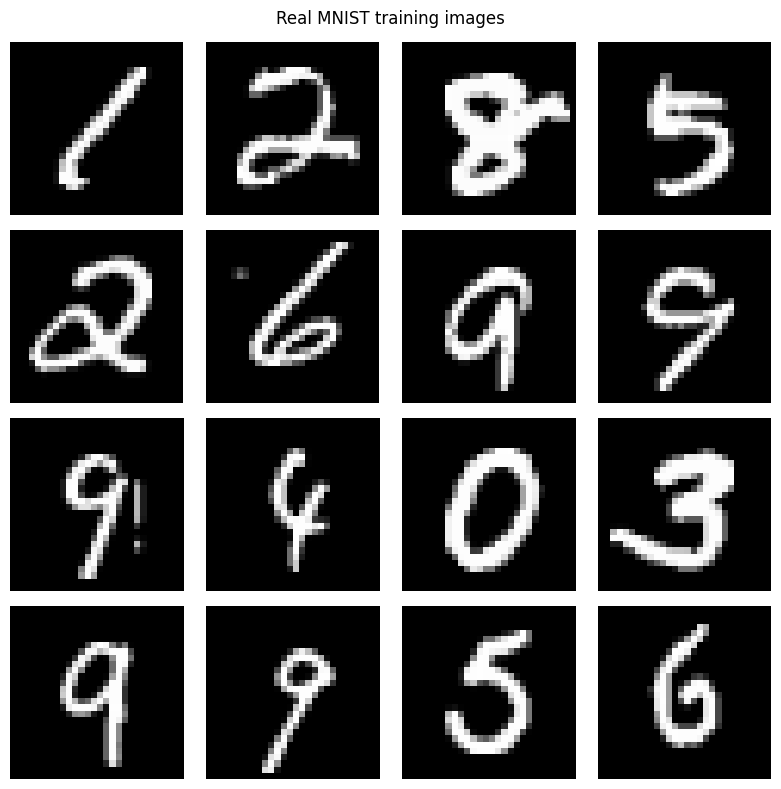

In [3]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = datasets.MNIST("./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=int(CONFIG["num_workers"]), pin_memory=(device.type == "cuda"), drop_last=False)
real_images, real_labels = next(iter(train_loader))
assert real_images.ndim == 4 and tuple(real_images.shape[1:]) == (1, 28, 28)
assert real_images.min() >= -1.01 and real_images.max() <= 1.01

def show_image_grid(images: torch.Tensor, title: str, nrow: int = 4) -> None:
    images = images.detach().cpu().clamp(-1, 1)
    rows = math.ceil(len(images) / nrow)
    fig, axes = plt.subplots(rows, nrow, figsize=(2*nrow, 2*rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images): ax.imshow(images[i, 0], cmap="gray", vmin=-1, vmax=1)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_image_grid(real_images[:16], "Real MNIST training images")

## 4. Linear training noise schedule

`betas[t]` is the variance increment, `alphas[t]=1-beta[t]`, and `alpha_bars[t]` is the cumulative product. Square-root terms implement forward noising; posterior variance is used by DDPM sampling. Each schedule array has shape `[T]`; `extract` reshapes selected values to `[B,1,1,1]` for broadcasting.

In [4]:
def make_noise_schedule(T: int, beta_start: float, beta_end: float, device: torch.device):
    assert T >= 2
    betas = torch.linspace(beta_start, beta_end, T, device=device, dtype=torch.float32)
    assert torch.all((betas > 0) & (betas < 1))
    alphas = 1. - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.)
    sqrt_alpha_bars = torch.sqrt(alpha_bars)
    sqrt_one_minus_alpha_bars = torch.sqrt(1. - alpha_bars)
    posterior_variance = (betas * (1. - alpha_bars_prev) / (1. - alpha_bars)).clamp(min=1e-20)
    return {"betas":betas, "alphas":alphas, "alpha_bars":alpha_bars,
        "alpha_bars_prev":alpha_bars_prev, "sqrt_alpha_bars":sqrt_alpha_bars,
        "sqrt_one_minus_alpha_bars":sqrt_one_minus_alpha_bars,
        "posterior_variance":posterior_variance}

schedule = make_noise_schedule(NUM_TIMESTEPS, float(CONFIG["beta_start"]), float(CONFIG["beta_end"]), device)
for name, value in schedule.items():
    assert value.shape == (NUM_TIMESTEPS,) and value.device.type == device.type
    print(name, tuple(value.shape), value.device)

def extract(values: torch.Tensor, t: torch.Tensor, x_shape: torch.Size) -> torch.Tensor:
    assert t.ndim == 1 and t.dtype == torch.long and x_shape[0] == t.shape[0]
    return values.gather(0, t).reshape(t.shape[0], *((1,) * (len(x_shape)-1)))

betas (300,) cuda:0
alphas (300,) cuda:0
alpha_bars (300,) cuda:0
alpha_bars_prev (300,) cuda:0
sqrt_alpha_bars (300,) cuda:0
sqrt_one_minus_alpha_bars (300,) cuda:0
posterior_variance (300,) cuda:0


## 5. Forward diffusion

The closed-form equation is `x_t=sqrt(alpha_bar_t)*x_0+sqrt(1-alpha_bar_t)*epsilon`. Batch items may have independent timesteps. Visualization reuses the same noise across levels.

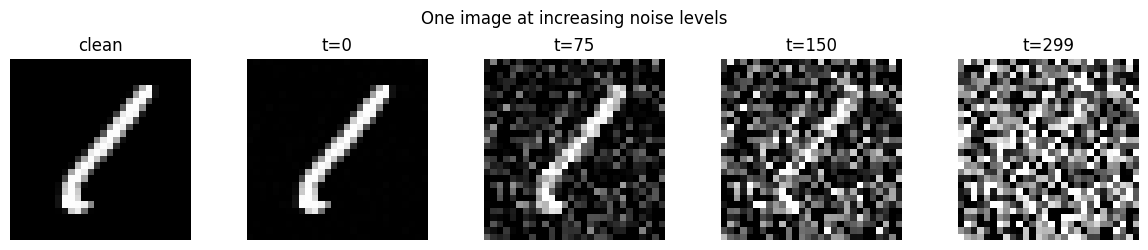

In [5]:
def q_sample(x0: torch.Tensor, t: torch.Tensor, noise: Optional[torch.Tensor] = None) -> torch.Tensor:
    assert x0.ndim == 4, f"Expected [B,C,H,W], got {tuple(x0.shape)}"
    assert t.shape == (x0.shape[0],), f"Expected [B], got {tuple(t.shape)}"
    assert t.device == x0.device == schedule["sqrt_alpha_bars"].device
    if noise is None: noise = torch.randn_like(x0)
    assert noise.shape == x0.shape and noise.device == x0.device
    xt = extract(schedule["sqrt_alpha_bars"], t, x0.shape)*x0 + extract(schedule["sqrt_one_minus_alpha_bars"], t, x0.shape)*noise
    assert xt.shape == x0.shape
    return xt

x_demo = real_images[:1].to(device)
levels = [0, NUM_TIMESTEPS//4, NUM_TIMESTEPS//2, NUM_TIMESTEPS-1]
fixed_noise = torch.randn_like(x_demo)
noisy = [q_sample(x_demo, torch.tensor([step], device=device), fixed_noise)[0,0].cpu() for step in levels]
fig, axes = plt.subplots(1, 5, figsize=(12, 2.5))
axes[0].imshow(x_demo[0,0].cpu(), cmap="gray", vmin=-1, vmax=1); axes[0].set_title("clean")
for ax, im, step in zip(axes[1:], noisy, levels): ax.imshow(im, cmap="gray", vmin=-1, vmax=1); ax.set_title(f"t={step}")
for ax in axes: ax.axis("off")
plt.suptitle("One image at increasing noise levels"); plt.tight_layout(); plt.show()
assert q_sample(real_images[:2].to(device), torch.tensor([0, NUM_TIMESTEPS//2], device=device)).shape == (2,1,28,28)

## 6. Sinusoidal timestep embeddings

Sinusoids encode a scalar timestep at multiple frequencies. An MLP projects the embedding; every residual block maps it to a per-channel bias that is broadcast over image height and width.

In [6]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim: int): super().__init__(); self.dim = dim
    def forward(self, t: torch.Tensor) -> torch.Tensor:
        assert t.ndim == 1
        half = self.dim // 2
        freq = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / max(half-1, 1))
        phase = t.float()[:, None] * freq[None, :]
        emb = torch.cat([phase.sin(), phase.cos()], dim=-1)
        return F.pad(emb, (0,1)) if self.dim % 2 else emb

class TimeResidualBlock(nn.Module):
    def __init__(self, cin: int, cout: int, time_dim: int):
        super().__init__()
        self.conv1=nn.Conv2d(cin,cout,3,padding=1); self.norm1=nn.GroupNorm(8,cout)
        self.conv2=nn.Conv2d(cout,cout,3,padding=1); self.norm2=nn.GroupNorm(8,cout)
        self.time_proj=nn.Linear(time_dim,cout)
        self.skip=nn.Identity() if cin==cout else nn.Conv2d(cin,cout,1)
    def forward(self,x:torch.Tensor,te:torch.Tensor)->torch.Tensor:
        h=self.norm1(self.conv1(x)); h=h+self.time_proj(te)[:,:,None,None]
        h=F.silu(h); h=self.norm2(self.conv2(h))
        return F.silu(h+self.skip(x))

## 7. Compact timestep-conditioned U-Net

The encoder downsamples and saves feature maps, the bottleneck processes low-resolution features, and the decoder upsamples. Skip connections concatenate encoder features at matching resolutions to retain digit details. Explicit resize targets preserve alignment; output noise has the exact input shape.

In [7]:
class SmallUNet(nn.Module):
    def __init__(self, base_channels: int = 32):
        super().__init__(); assert base_channels % 8 == 0
        c1,c2,c3=base_channels,2*base_channels,4*base_channels; td=4*base_channels
        self.time_mlp=nn.Sequential(SinusoidalTimeEmbedding(td),nn.Linear(td,td),nn.SiLU(),nn.Linear(td,td))
        self.input=nn.Conv2d(1,c1,3,padding=1); self.down1=TimeResidualBlock(c1,c1,td)
        self.ds1=nn.Conv2d(c1,c2,4,stride=2,padding=1); self.down2=TimeResidualBlock(c2,c2,td)
        self.ds2=nn.Conv2d(c2,c3,4,stride=2,padding=1)
        self.mid1=TimeResidualBlock(c3,c3,td); self.mid2=TimeResidualBlock(c3,c3,td)
        self.up2=TimeResidualBlock(c3+c2,c2,td); self.up1=TimeResidualBlock(c2+c1,c1,td)
        self.out_norm=nn.GroupNorm(8,c1); self.out=nn.Conv2d(c1,1,3,padding=1)
    def forward(self,x:torch.Tensor,t:torch.Tensor)->torch.Tensor:
        assert x.ndim==4 and tuple(x.shape[1:])==(1,28,28), f"Bad image shape {tuple(x.shape)}"
        assert t.shape==(x.shape[0],)
        te=self.time_mlp(t); x1=self.down1(self.input(x),te)       # B,c1,28,28
        x2=self.down2(self.ds1(x1),te)                             # B,c2,14,14
        h=self.mid2(self.mid1(self.ds2(x2),te),te)                 # B,c3,7,7
        h=F.interpolate(h,size=x2.shape[-2:],mode="nearest")
        h=self.up2(torch.cat([h,x2],dim=1),te)
        h=F.interpolate(h,size=x1.shape[-2:],mode="nearest")
        h=self.up1(torch.cat([h,x1],dim=1),te)
        out=self.out(F.silu(self.out_norm(h)))
        assert out.shape==x.shape, f"{tuple(out.shape)} != {tuple(x.shape)}"
        return out

model=SmallUNet(int(CONFIG["base_channels"])).to(device)
with torch.no_grad():
    assert model(torch.randn(2,1,28,28,device=device),torch.zeros(2,dtype=torch.long,device=device)).shape==(2,1,28,28)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 1139969


## 8. DDIM and DDPM reverse samplers

Both samplers share this notebook's trained epsilon predictor and original training schedule. DDPM performs ancestral steps at every training timestep. DDIM uses a shorter selected sequence. For current `t` and previous selected `s`, estimate `x0`, then use `x_s=sqrt(alpha_bar_s)*x0+sqrt(1-alpha_bar_s-sigma^2)*epsilon+sigma*z`, where `sigma=eta*sqrt((1-alpha_bar_s)/(1-alpha_bar_t)*(1-alpha_bar_t/alpha_bar_s))`. Eta zero is deterministic given initial noise; the final transition uses `alpha_bar_s=1` and returns the clean estimate.

In [8]:
def extract_at(values,index,x):
    assert 0<=index<len(values)
    return values[index].reshape(1,1,1,1).to(device=x.device,dtype=x.dtype)

def select_timesteps(training_steps,inference_steps,device):
    assert 1<=inference_steps<=training_steps
    idx=torch.linspace(0,training_steps-1,inference_steps,device=device).round().long()
    assert idx.numel()==inference_steps and torch.unique(idx).numel()==inference_steps
    assert int(idx[0])>=0 and int(idx[-1])<training_steps and torch.all(idx[1:]>idx[:-1])
    return idx

@torch.no_grad()
def ddim_sample(model,count,inference_steps,eta=0.0,initial_noise=None,show_progress=False):
    assert eta>=0 and 1<=inference_steps<=NUM_TIMESTEPS
    dev=next(model.parameters()).device; selected=select_timesteps(NUM_TIMESTEPS,inference_steps,dev)
    steps=[int(v) for v in selected.cpu().tolist()]
    x=torch.randn(count,1,28,28,device=dev) if initial_noise is None else initial_noise.clone()
    assert x.shape==(count,1,28,28) and x.device==dev
    model.eval(); it=reversed(list(enumerate(steps)))
    if show_progress: it=tqdm(it,total=len(steps),desc=f"DDIM {inference_steps}",leave=False)
    for pos,t_idx in it:
        s_idx=steps[pos-1] if pos>0 else -1
        abt=extract_at(schedule["alpha_bars"],t_idx,x)
        t=torch.full((count,),t_idx,device=dev,dtype=torch.long); eps=model(x,t)
        assert eps.shape==x.shape
        x0=((x-torch.sqrt(1-abt)*eps)/torch.sqrt(abt)).clamp(-1,1)
        abs_=torch.ones_like(abt) if s_idx<0 else extract_at(schedule["alpha_bars"],s_idx,x)
        ratio=((1-abs_)/(1-abt).clamp(min=1e-20))*(1-abt/abs_)
        sigma=eta*torch.sqrt(ratio.clamp(min=0)); direction_sq=1-abs_-sigma.square()
        assert torch.all(direction_sq>=-1e-6)
        x=torch.sqrt(abs_)*x0+torch.sqrt(direction_sq.clamp(min=0))*eps
        if s_idx>=0 and eta>0: x=x+sigma*torch.randn_like(x)
        assert x.shape==(count,1,28,28) and torch.isfinite(x).all()
    return x.clamp(-1,1)

@torch.no_grad()
def ddpm_sample(model,count,initial_noise=None,show_progress=False):
    dev=next(model.parameters()).device
    x=torch.randn(count,1,28,28,device=dev) if initial_noise is None else initial_noise.clone()
    assert x.shape==(count,1,28,28) and x.device==dev
    model.eval(); it=reversed(range(NUM_TIMESTEPS))
    if show_progress: it=tqdm(it,total=NUM_TIMESTEPS,desc="DDPM",leave=False)
    for ti in it:
        t=torch.full((count,),ti,device=dev,dtype=torch.long)
        beta=extract_at(schedule["betas"],ti,x); alpha=extract_at(schedule["alphas"],ti,x)
        ab=extract_at(schedule["alpha_bars"],ti,x); eps=model(x,t)
        mean=(x-beta/torch.sqrt(1-ab)*eps)/torch.sqrt(alpha)
        x=mean+torch.sqrt(extract_at(schedule["posterior_variance"],ti,x))*torch.randn_like(x) if ti>0 else mean
    return x.clamp(-1,1)

def sample(model,count,schedule):
    return ddim_sample(model,count,min(int(CONFIG["inference_steps"][0]),NUM_TIMESTEPS),float(CONFIG["ddim_eta"]))

## 9. Train an independent model

Initialize a new model and optimizer in this notebook. Each image gets an independent timestep and noise; optimize MSE against that exact injected noise. Resume only from this notebook's checkpoint. Periodic generated grids use DDIM.

Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1: mean noise-prediction MSE=0.13236


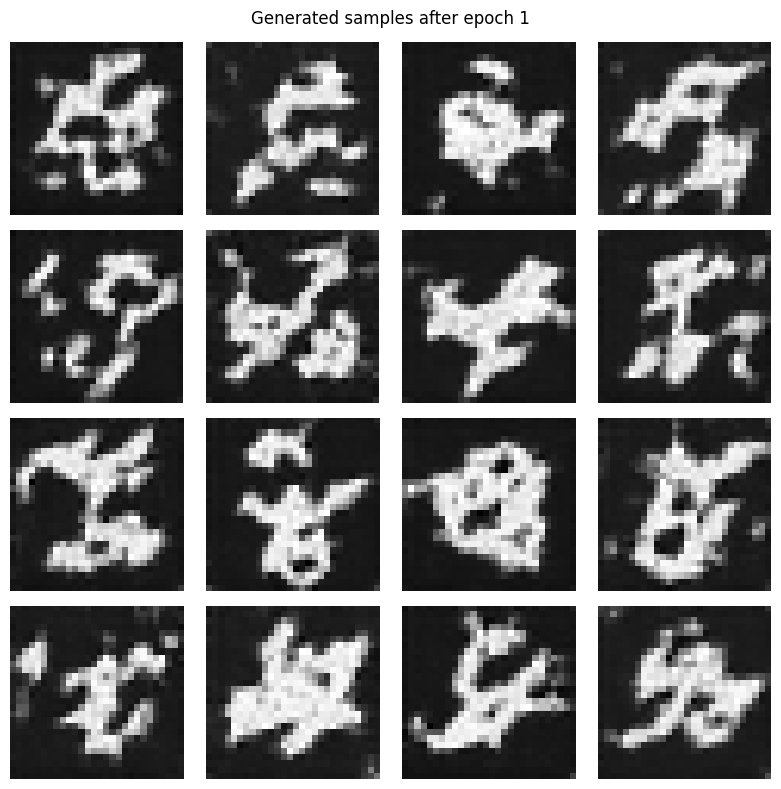

Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2: mean noise-prediction MSE=0.06358


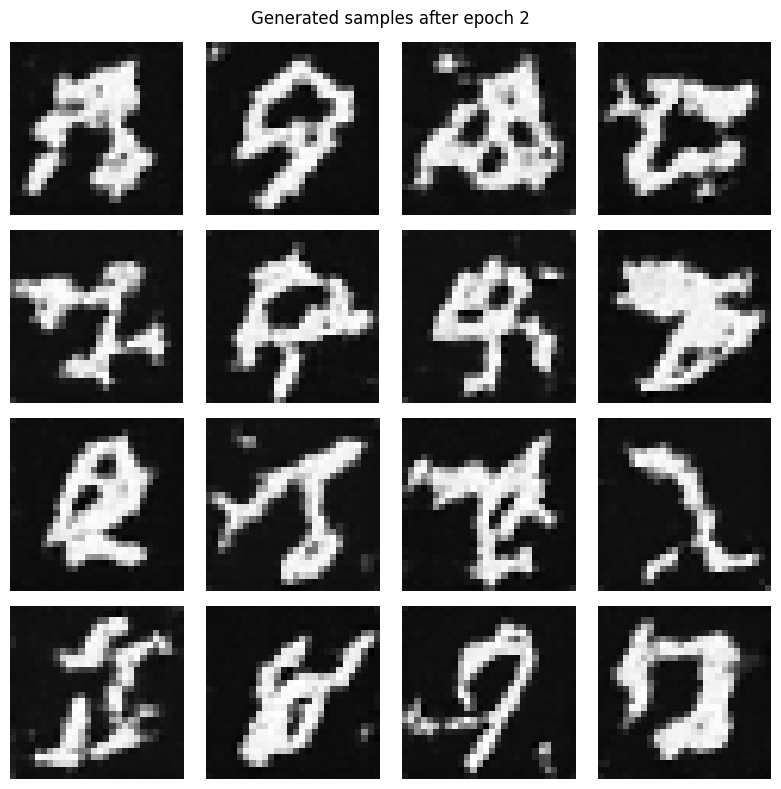

Epoch 3/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 3: mean noise-prediction MSE=0.05555


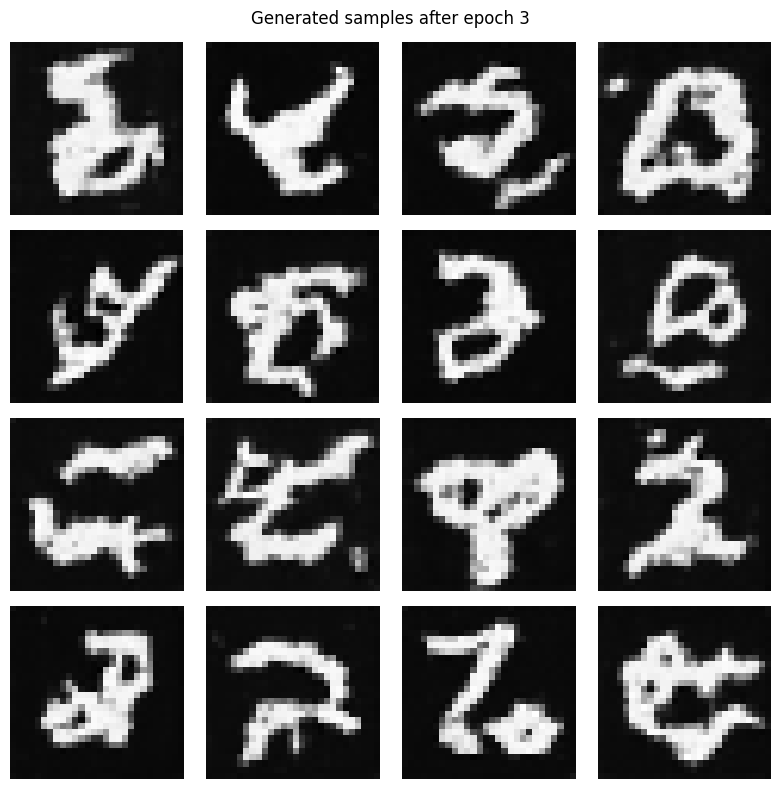

Epoch 4/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 4: mean noise-prediction MSE=0.05143


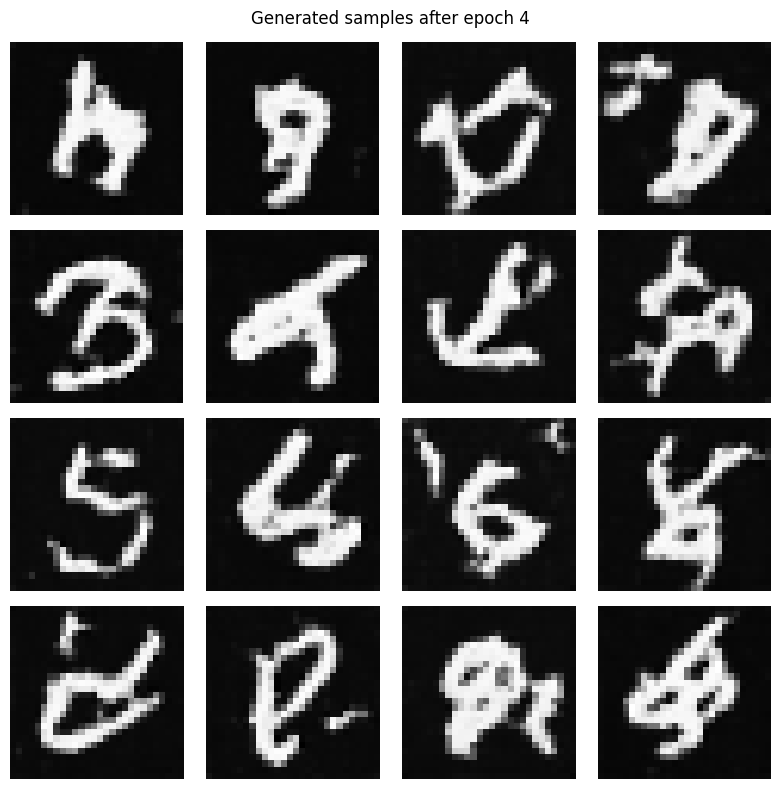

Epoch 5/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 5: mean noise-prediction MSE=0.04943


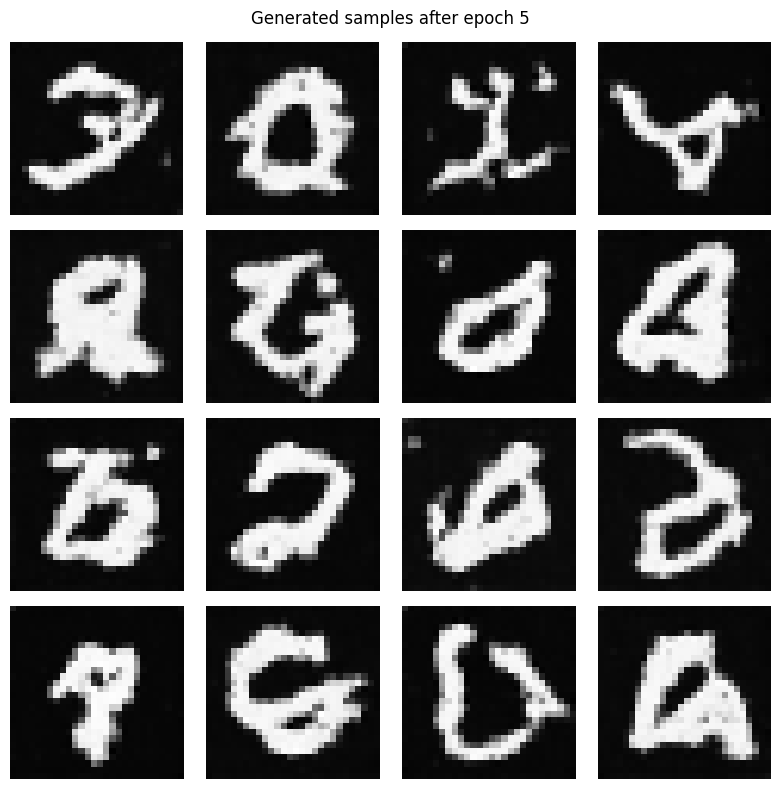

Epoch 6/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 6: mean noise-prediction MSE=0.04788


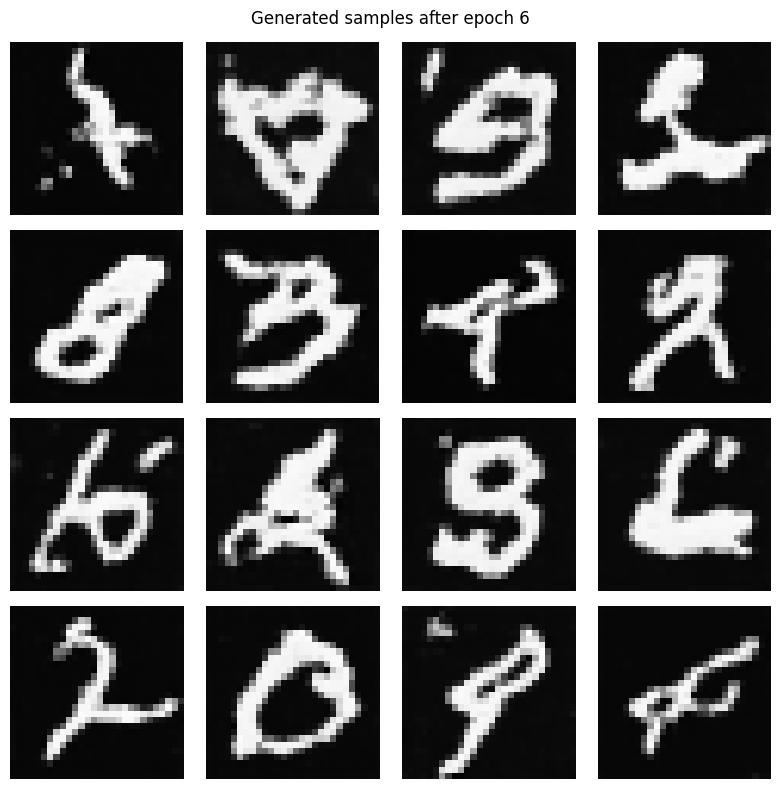

Epoch 7/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 7: mean noise-prediction MSE=0.04650


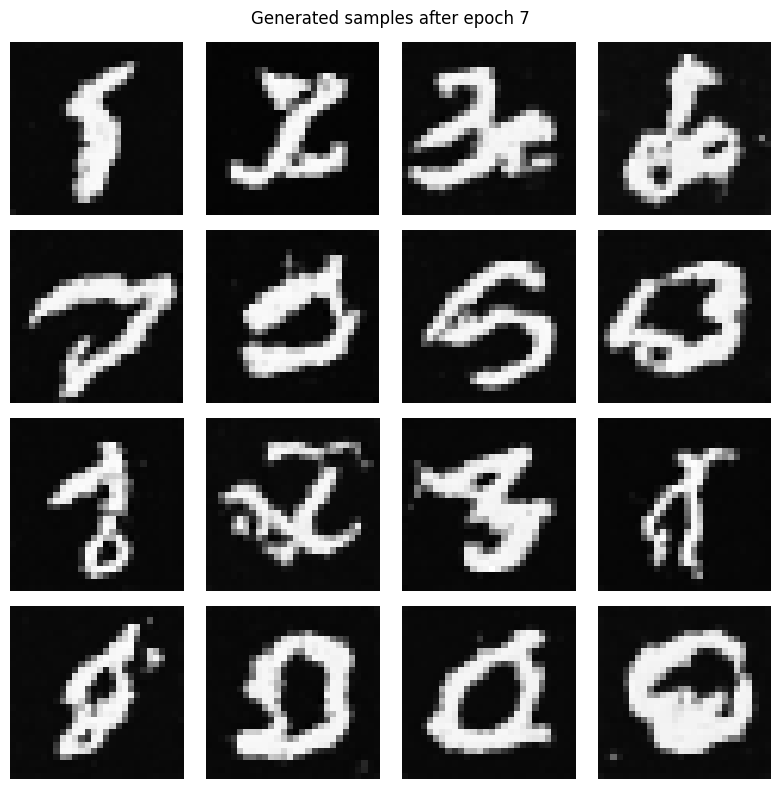

Epoch 8/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 8: mean noise-prediction MSE=0.04534


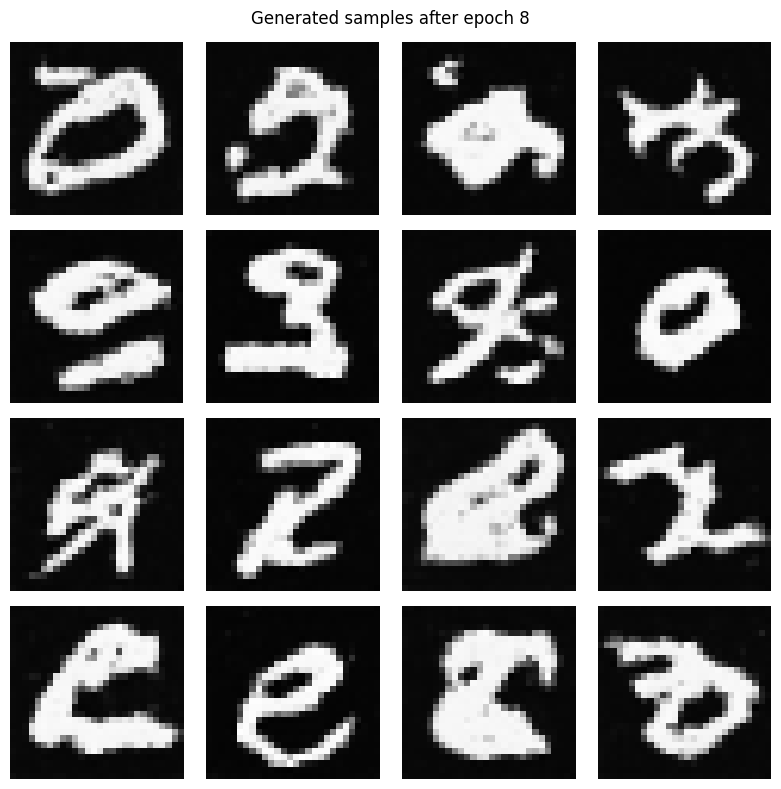

Epoch 9/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 9: mean noise-prediction MSE=0.04439


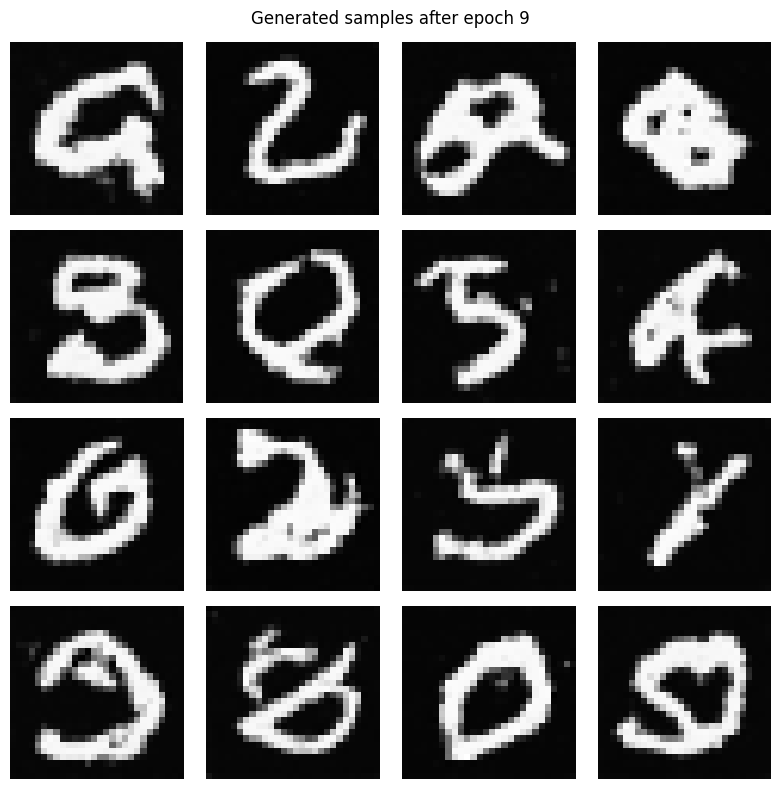

Epoch 10/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 10: mean noise-prediction MSE=0.04393


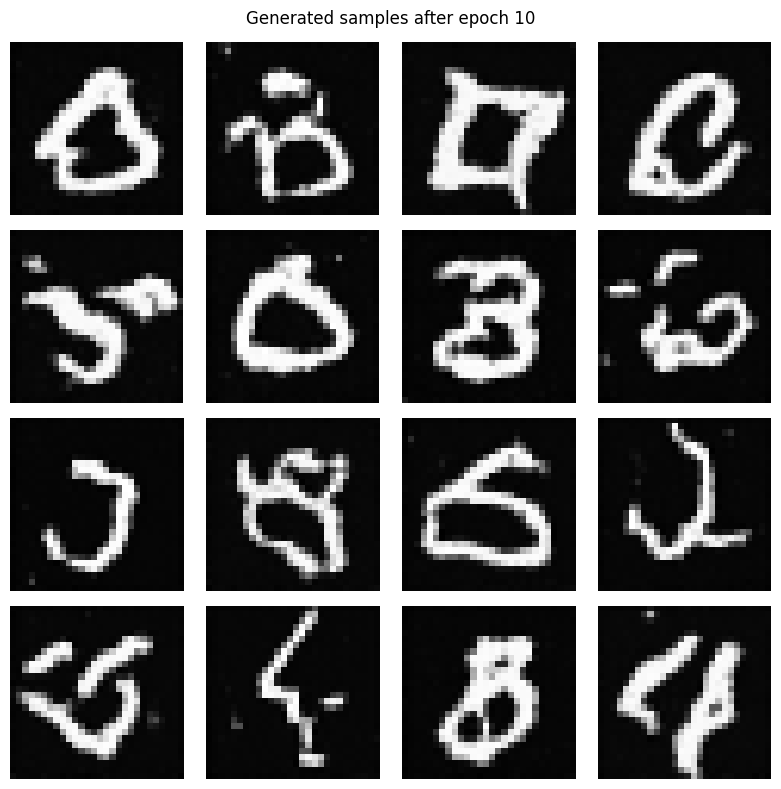

Epoch 11/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 11: mean noise-prediction MSE=0.04355


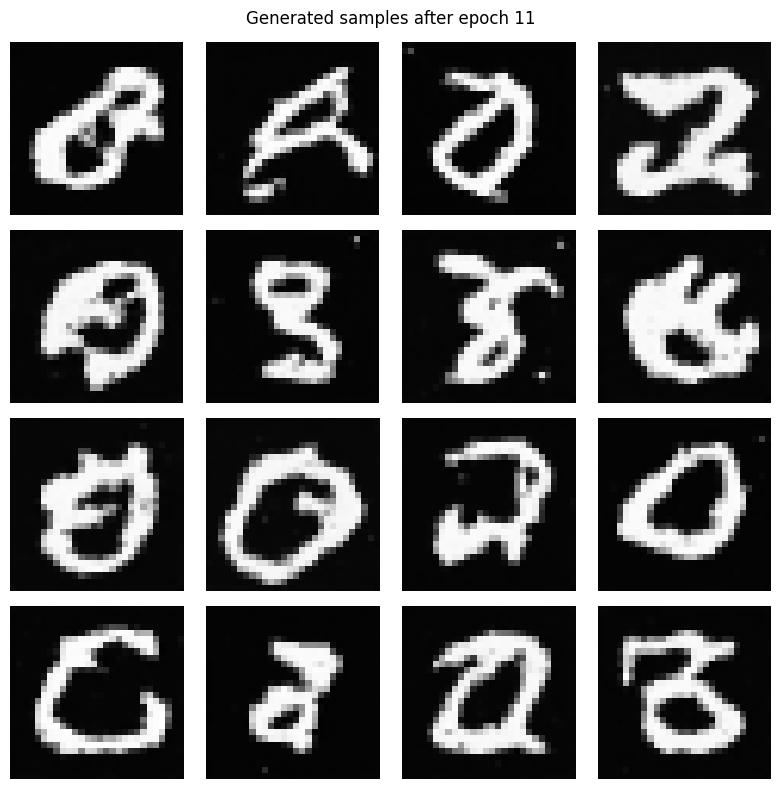

Epoch 12/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 12: mean noise-prediction MSE=0.04325


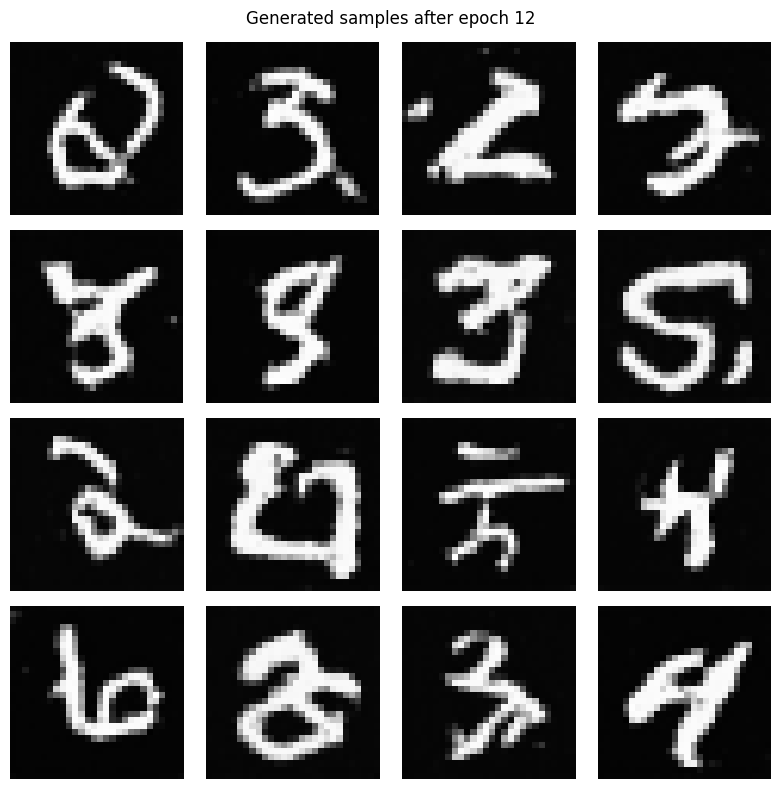

Epoch 13/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 13: mean noise-prediction MSE=0.04274


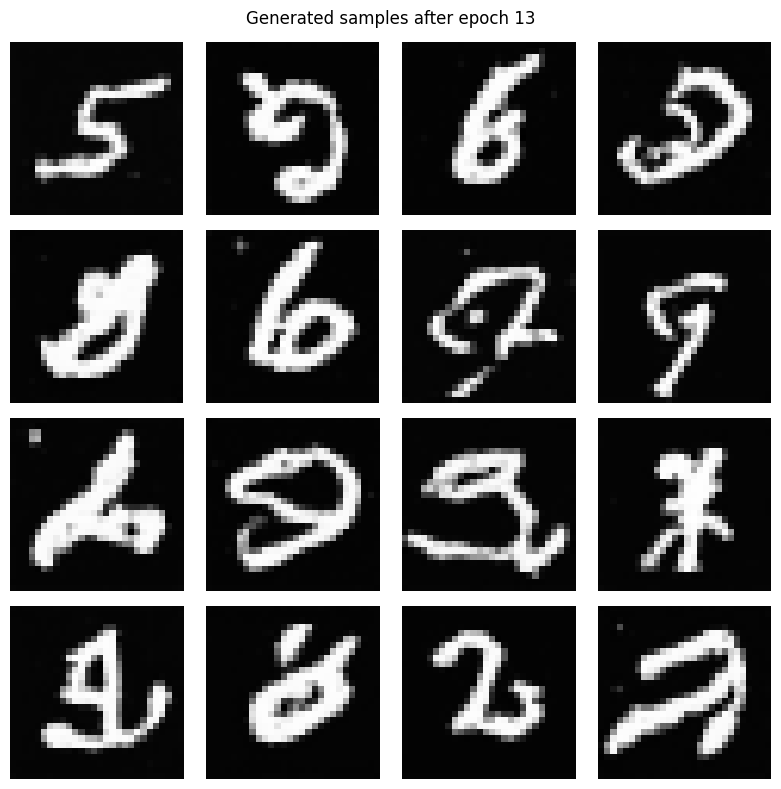

Epoch 14/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 14: mean noise-prediction MSE=0.04194


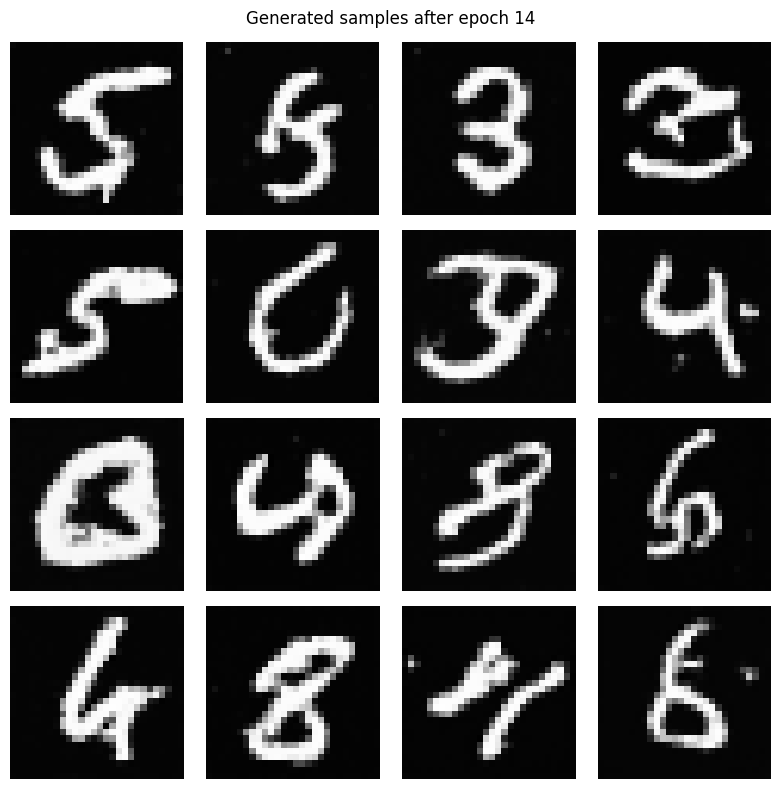

Epoch 15/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 15: mean noise-prediction MSE=0.04169


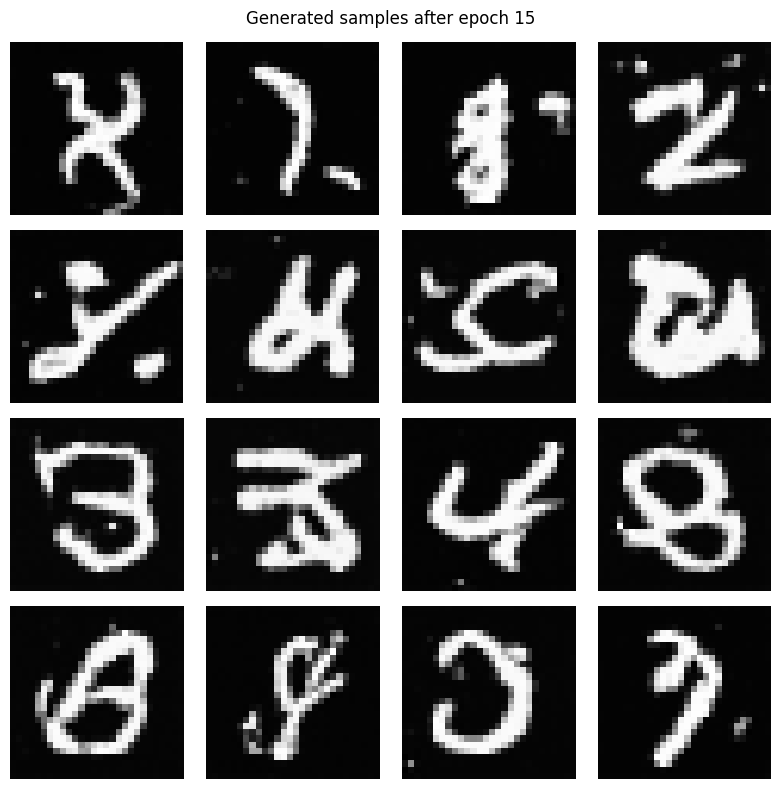

Epoch 16/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 16: mean noise-prediction MSE=0.04157


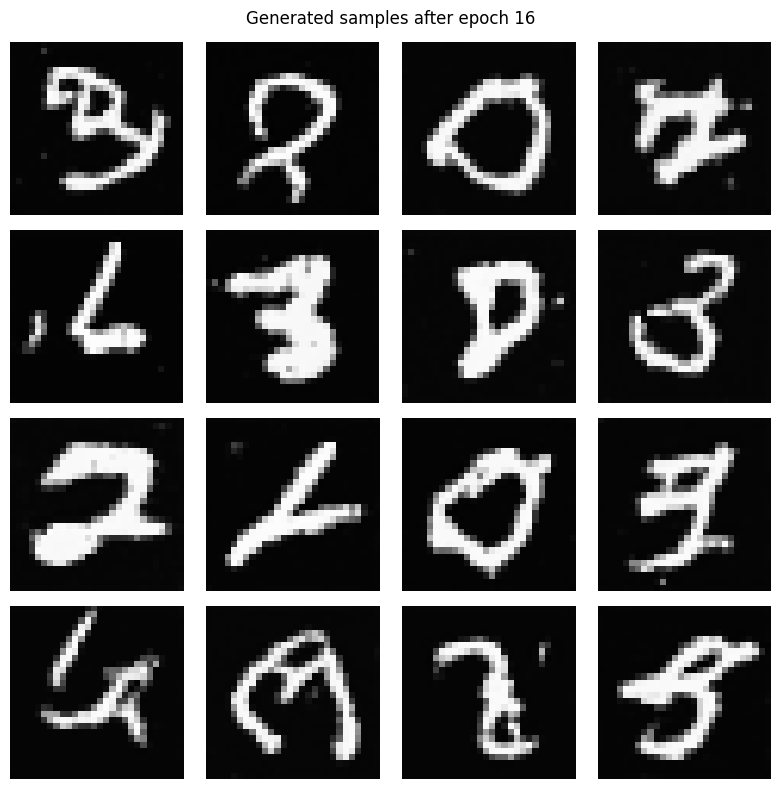

Epoch 17/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 17: mean noise-prediction MSE=0.04119


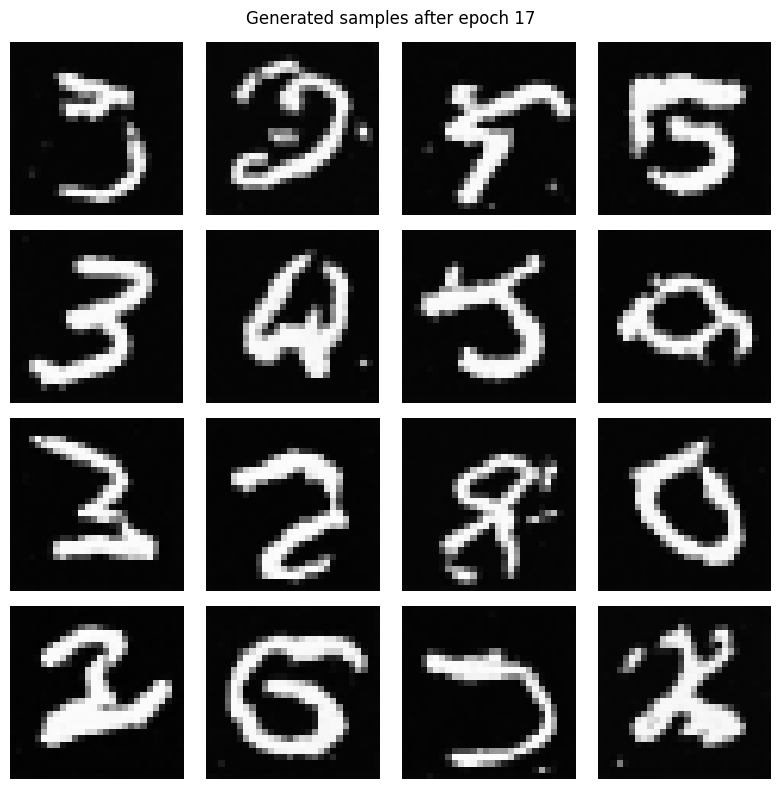

Epoch 18/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 18: mean noise-prediction MSE=0.04084


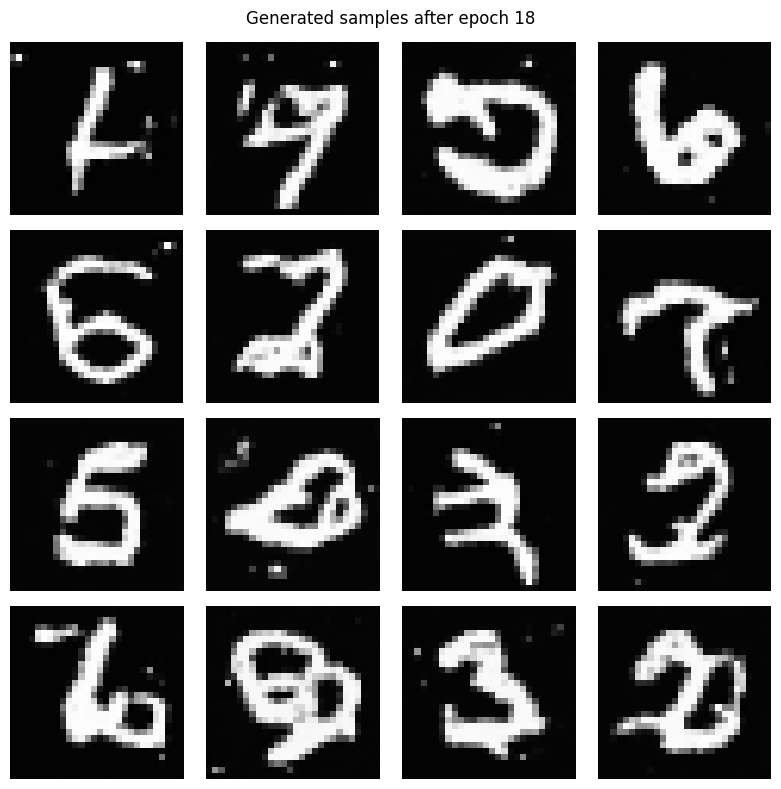

Epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 19: mean noise-prediction MSE=0.04093


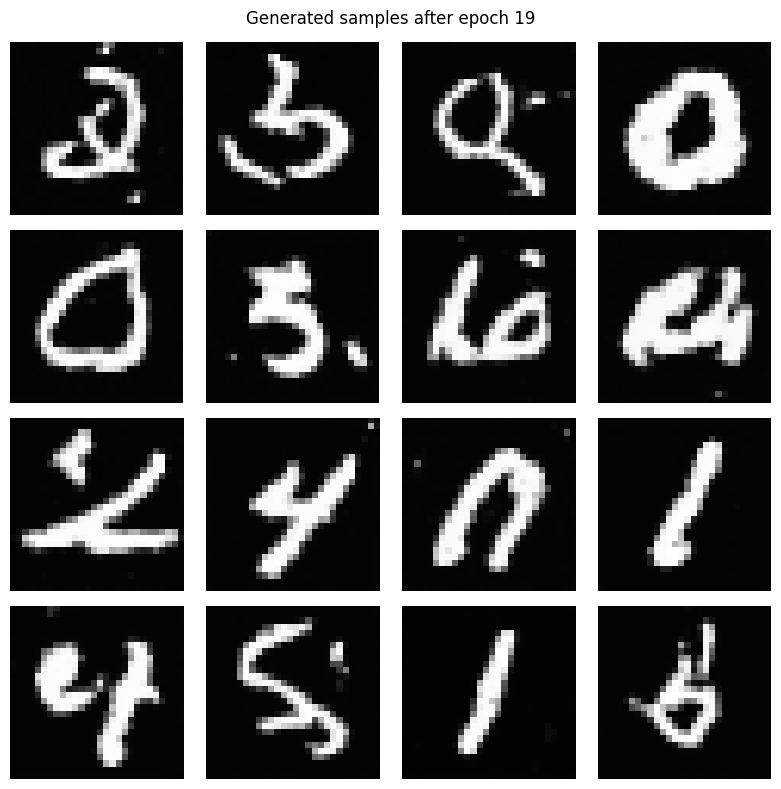

Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 20: mean noise-prediction MSE=0.04062


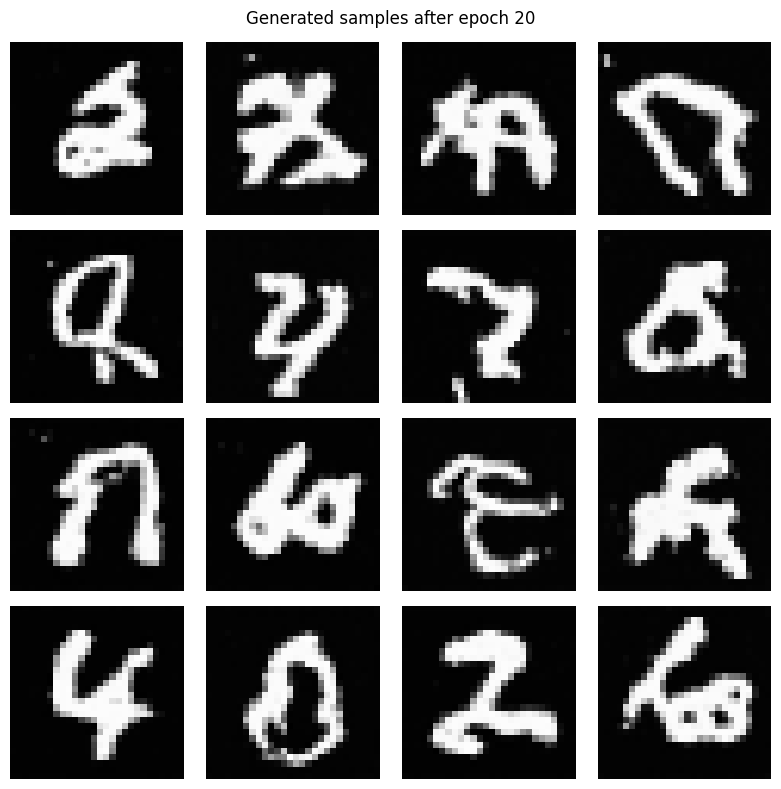

Training loop finished; this does not guarantee sample quality.


In [9]:
optimizer=torch.optim.AdamW(model.parameters(),lr=float(CONFIG["learning_rate"]))
start_epoch=0; loss_history=[]
if CONFIG["resume"] and CHECKPOINT_PATH.exists():
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device,weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"]); optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch=int(checkpoint["epoch"]); loss_history=list(checkpoint.get("loss_history",[]))
    print("Resumed at epoch",start_epoch)
elif CONFIG["resume"]: print("Checkpoint missing; starting fresh.")

@torch.no_grad()
def save_training_samples(epoch:int)->None:
    was_training=model.training; images=sample(model,int(CONFIG["sample_count"]),schedule)
    show_image_grid(images,f"Generated samples after epoch {epoch}")
    if was_training: model.train()

def save_checkpoint(epoch:int,mean_loss:float)->None:
    torch.save({"epoch":epoch,"model_state_dict":model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),"config":dict(CONFIG),"seed":SEED,
        "mean_loss":mean_loss,"loss_history":list(loss_history)},CHECKPOINT_PATH)

for epoch in range(start_epoch,int(CONFIG["epochs"])):
    model.train(); total=0.; batches=0
    iterator=tqdm(train_loader,desc=f"Epoch {epoch+1}/{CONFIG['epochs']}",leave=True,
        disable=not bool(CONFIG["show_progress"]))
    for x0,_ in iterator:
        x0=x0.to(device,non_blocking=True); b=x0.shape[0]
        t=torch.randint(0,NUM_TIMESTEPS,(b,),device=device,dtype=torch.long)
        noise=torch.randn_like(x0); xt=q_sample(x0,t,noise); predicted=model(xt,t)
        assert predicted.shape==noise.shape
        loss=F.mse_loss(predicted,noise)
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        total+=loss.item(); batches+=1; iterator.set_postfix(loss=f"{loss.item():.4f}")
    mean_loss=total/max(batches,1); loss_history.append(mean_loss); done=epoch+1
    save_checkpoint(done,mean_loss)
    print(f"Epoch {done}: mean noise-prediction MSE={mean_loss:.5f}")
    if done % int(CONFIG["sample_every_epochs"])==0: save_training_samples(done)
print("Training loop finished; this does not guarantee sample quality.")

## 10. Training loss and generated samples

A decreasing noise-prediction loss does not guarantee perfect digits: sample quality depends on model capacity, schedule, training duration, and sampling settings. Results appear only after executing the notebook.

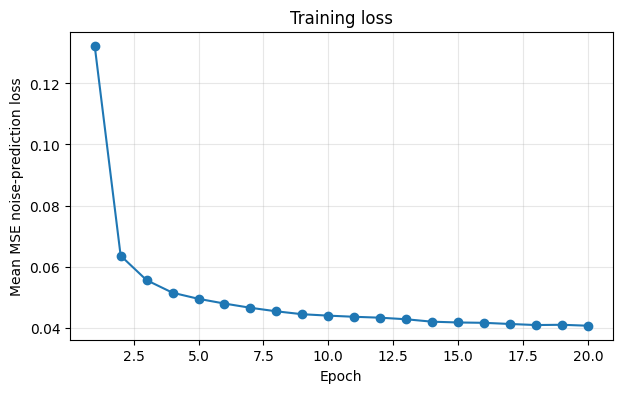

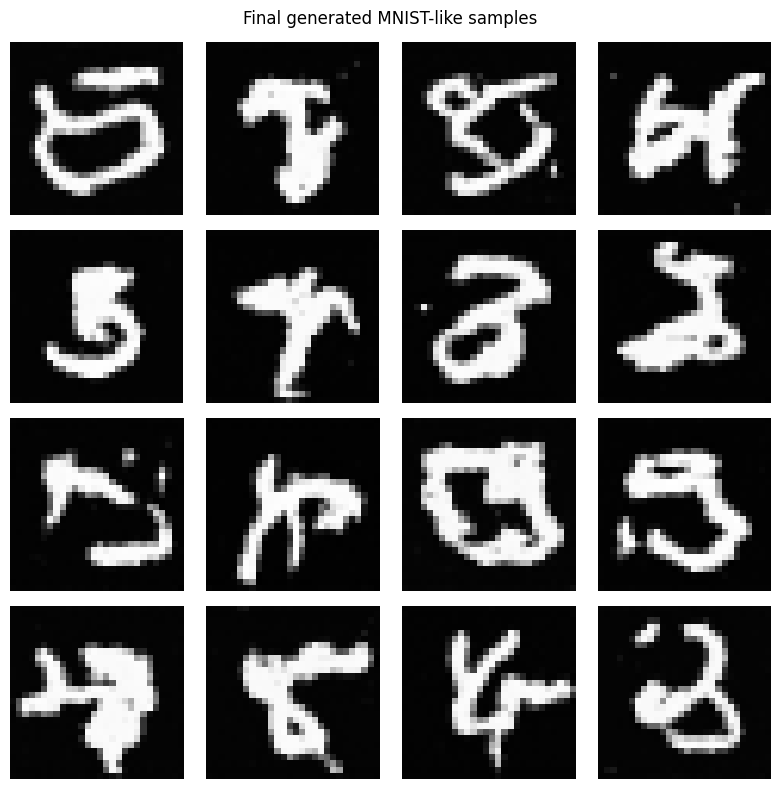

In [10]:
if loss_history:
    plt.figure(figsize=(7,4)); plt.plot(range(1,len(loss_history)+1),loss_history,marker="o")
    plt.xlabel("Epoch"); plt.ylabel("Mean MSE noise-prediction loss"); plt.title("Training loss")
    plt.grid(alpha=.3); plt.show()
else: print("No training history yet; run the training cell first.")
final_samples=sample(model,int(CONFIG["sample_count"]),schedule)
show_image_grid(final_samples,"Final generated MNIST-like samples")

## 11. Real, forward-noised, and generated images

The noised row uses a common timestep for visibility; training samples timesteps independently.

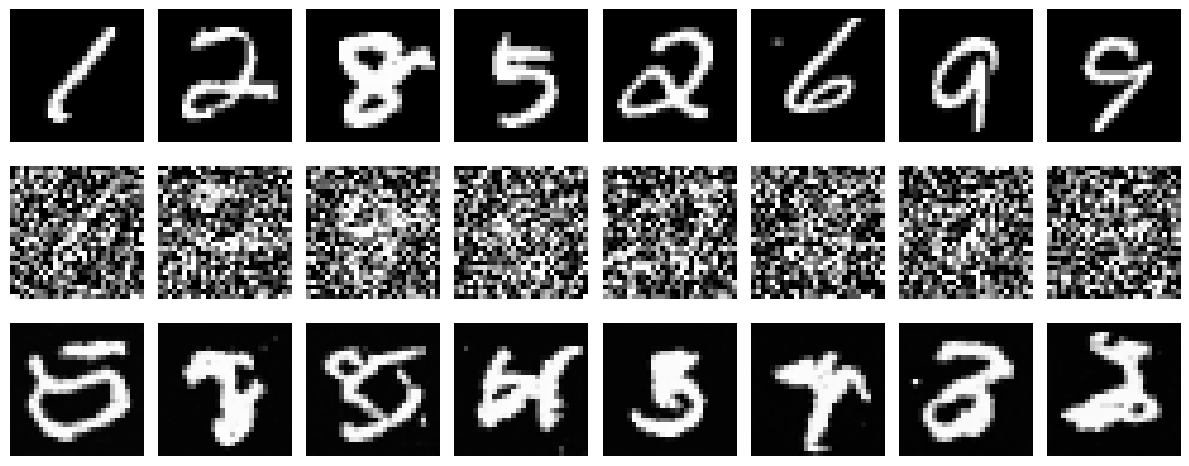

In [11]:
n=8; real=real_images[:n].to(device)
t_vis=torch.full((n,),NUM_TIMESTEPS*3//4,device=device,dtype=torch.long)
noised=q_sample(real,t_vis); generated=final_samples[:n]
fig,axes=plt.subplots(3,n,figsize=(n*1.5,5))
for r,(imgs,label) in enumerate([(real,"Real"),(noised,f"Noised (t={int(t_vis[0])})"),(generated,"Generated")]):
    for c in range(n):
        axes[r,c].imshow(imgs[c,0].detach().cpu().clamp(-1,1),cmap="gray",vmin=-1,vmax=1); axes[r,c].axis("off")
    axes[r,0].set_ylabel(label,rotation=0,labelpad=45,va="center")
plt.tight_layout(); plt.show()

Measured on cuda
DDIM 25 eta=0            evals= 25, runtime=0.115s
DDIM 50 eta=0            evals= 50, runtime=0.200s
DDIM 100 eta=0           evals=100, runtime=0.397s
DDIM 25 eta=0.5          evals= 25, runtime=0.112s
DDPM 300 steps           evals=300, runtime=1.096s


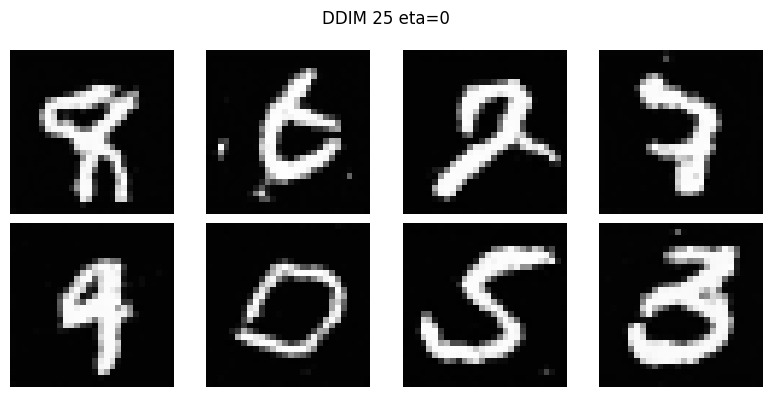

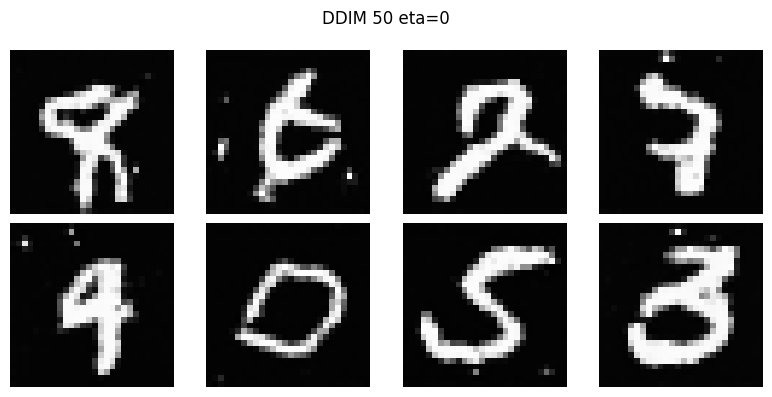

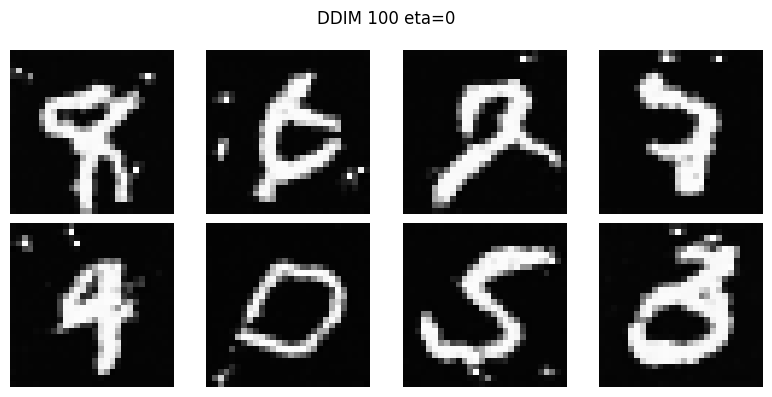

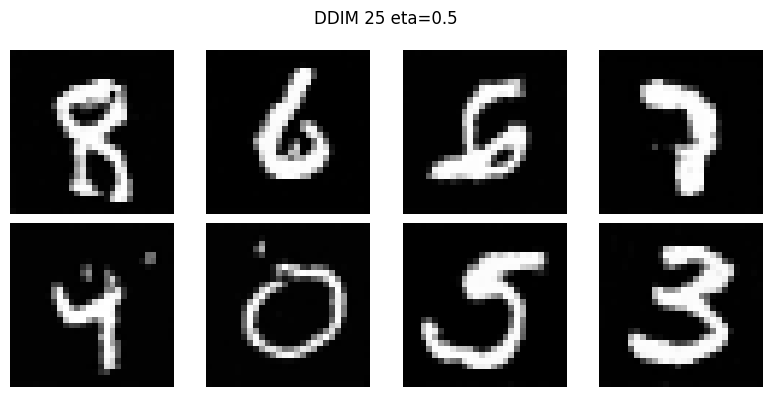

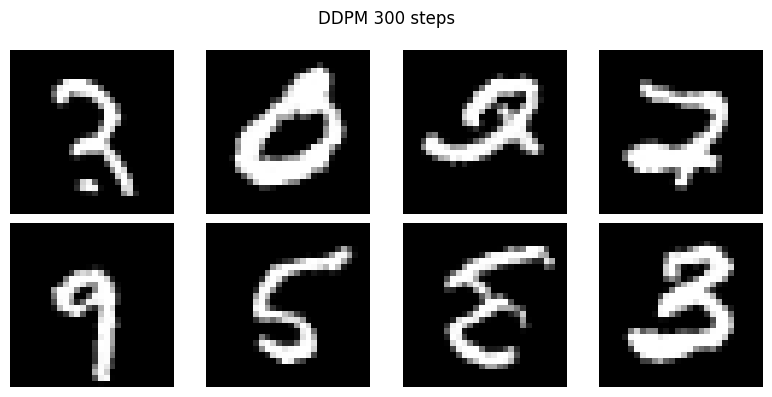

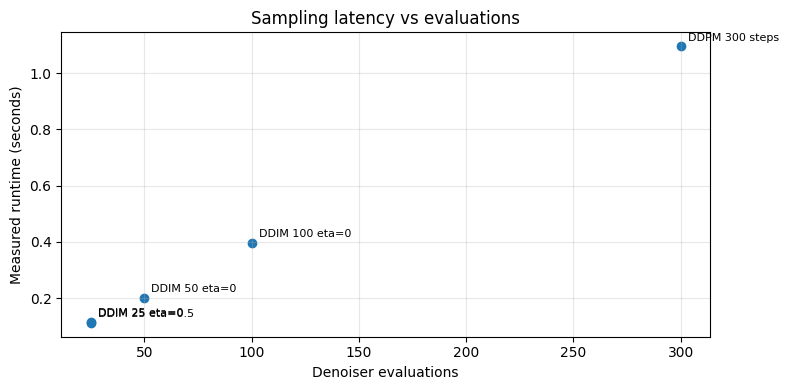

In [12]:

def sync_device():
    if device.type=="cuda": torch.cuda.synchronize()
def timed(fn):
    sync_device(); start=time.perf_counter(); out=fn(); sync_device(); return out,time.perf_counter()-start
n=min(8,int(CONFIG["sample_count"])); initial=torch.randn(n,1,28,28,device=device)
results={}; runtimes={}; evals={}; short=min(25,NUM_TIMESTEPS)
a,sec=timed(lambda:ddim_sample(model,n,short,0.0,initial)); b=ddim_sample(model,n,short,0.0,initial)
assert torch.allclose(a,b,atol=1e-6,rtol=1e-5)
label=f"DDIM {short} eta=0"; results[label]=a; runtimes[label]=sec; evals[label]=short
for ns in sorted(set(int(v) for v in CONFIG["inference_steps"])):
    if ns>NUM_TIMESTEPS or ns==short: continue
    eta=float(CONFIG["ddim_eta"]); label=f"DDIM {ns} eta={eta:g}"
    results[label],runtimes[label]=timed(lambda ns=ns,eta=eta:ddim_sample(model,n,ns,eta,initial)); evals[label]=ns
eta_value=0.5; label=f"DDIM {short} eta={eta_value:g}"
results[label],runtimes[label]=timed(lambda:ddim_sample(model,n,short,eta_value,initial)); evals[label]=short
label=f"DDPM {NUM_TIMESTEPS} steps"; results[label],runtimes[label]=timed(lambda:ddpm_sample(model,n,initial)); evals[label]=NUM_TIMESTEPS
print("Measured on",device)
for label in results: print(f"{label:24s} evals={evals[label]:3d}, runtime={runtimes[label]:.3f}s")
for label,images in results.items(): show_image_grid(images,label,nrow=4)
fig,ax=plt.subplots(figsize=(8,4)); ax.scatter([evals[k] for k in results],[runtimes[k] for k in results])
for k in results: ax.annotate(k,(evals[k],runtimes[k]),xytext=(5,4),textcoords="offset points",fontsize=8)
ax.set_xlabel("Denoiser evaluations"); ax.set_ylabel("Measured runtime (seconds)"); ax.set_title("Sampling latency vs evaluations"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 13. Troubleshooting and checklist

- Invalid timestep sequences must be unique, in range, and ascending before reverse traversal.
- Use the original training `alpha_bars[t]` and `alpha_bars[s]` for the current and previous selected indices.
- For broadcasting, reshape schedule scalars to `[1,1,1,1]` or `[B,1,1,1]`.
- Clamp tiny negative square-root arguments from precision error; validate eta and timestep pairs.
- Reduce batch size, sample count, or `base_channels` (divisible by 8) for CUDA out-of-memory errors.
- Poor samples can result from insufficient training; fewer inference steps reduce calls and often latency but may degrade quality.
- With eta zero and fixed initial noise, results should repeat under deterministic execution; some GPU kernels can vary slightly.

Verify the cumulative-alpha forward equation, exact injected-noise training target, matched training schedule, DDIM clean final transition, and DDPM posterior noise only for `t>0`.